In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../')

import oasis_dla

In [2]:
def linear_indep(mats: list[np.ndarray]) -> bool:
    vecs = [m.flatten() for m in mats]
    M = np.column_stack(vecs)
    rank = np.linalg.matrix_rank(M)
    return rank == M.shape[1]

def commutator(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    return A @ B - B @ A

def construct_dla(generators):
    dla = [] # init empty dla to start

    # go through initial generators
    for gen in generators:
        # print(type(gen))
        pot_dla = [*dla, gen]
        print(pot_dla)
        if linear_indep(pot_dla):
            dla = pot_dla

    # now we're left w all the linear indep generators 
    # go thru all combinations of generators and compute brackets, find
    l = 1
    r = 0

    while l < len(dla):
        for m in range(r):
            bracket = commutator(dla[l], dla[m])
            pot_dla = [*dla, bracket]
            if linear_indep(pot_dla):
                dla = pot_dla
        r += 1
        if r == l:
            l += 1
            r = 0

    return dla
         




In [3]:
circuit = qiskit.QuantumCircuit(1)
circuit.h(0)
circuit.ry(0, 0)

gen = oasis_dla.extract_generators(circuit)

display(gen)

X = qiskit.circuit.library.XGate().to_matrix()
Y = qiskit.circuit.library.YGate().to_matrix()
Z = qiskit.circuit.library.ZGate().to_matrix()

dla = construct_dla(gen)

print(f"Computed DLA: \n{dla}")
print(f"dim(g): {len(dla)}")

[array([[-1.+0.j,  1.+0.j],
        [ 1.+0.j,  1.+0.j]]),
 array([[0.+0.j, 0.-1.j],
        [0.+1.j, 0.+0.j]])]

[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]])]
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]])]
Computed DLA: 
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]])]
dim(g): 2


In [4]:
print(f"Var(cost) ~ 1/dim(g) = {1/len(dla)}")

Var(cost) ~ 1/dim(g) = 0.5


In [5]:
vqls = oasis_dla.VQLS()

A = np.array([
    [1, 1],
    [0, 5]
])

b = np.array([
    [1],
    [-1]
])

X = np.array([
    [0, 1],
    [1, 0]
])

Y = np.array([
    [0, -1j],
    [1j, 0]
])

Z = np.array([
    [1, 0],
    [0, -1]
])

# pauli_matrices = [np.eye(2), X, Y, Z]
# coeffs = [0.5 * np.trace(P @ A) for P in pauli_matrices]

# sum = np.zeros((2, 2), np.complex128)
# for i, p in enumerate(pauli_matrices):
#     sum += (coeffs[i] * p)
# sum

solution = vqls.solve(A, b, shots=10_000)

print(solution.solution())
solution.get_probabilities()
print(np.linalg.solve(A, b))


 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 6.661338147750939e-16
       x: [ 4.382e+00]
     nit: 46
   maxcv: 0.0
    nfev: 26
[[ 1.20003663+0.01454417j]
 [-0.19921682+0.00363604j]]
[[ 1.2]
 [-0.2]]


 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -4.440892098500626e-16
       x: [ 4.382e+00]
     nit: 44
   maxcv: 0.0
    nfev: 26
[{'0': 0.972, '1': 0.028}]
classical probabilities: [0.97297297 0.02702703]


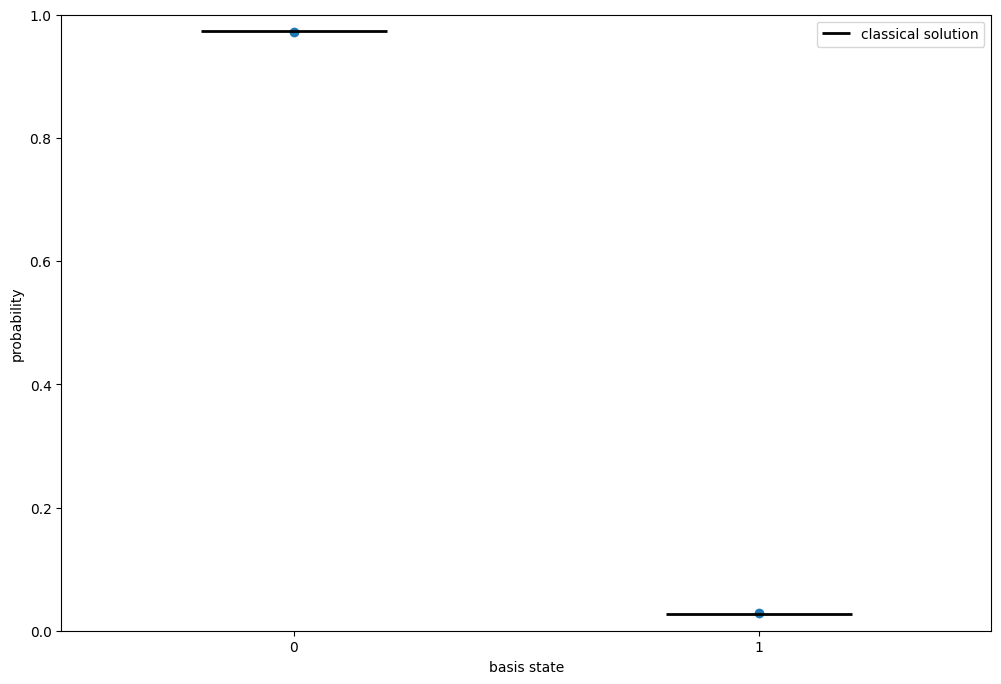

In [6]:
prob_list = []
for i in range(0, 1):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -1.3322676295501878e-15
       x: [ 4.382e+00]
     nit: 41
   maxcv: 0.0
    nfev: 20
[{'0': 0.9749, '1': 0.0251}]
classical probabilities: [0.97297297 0.02702703]


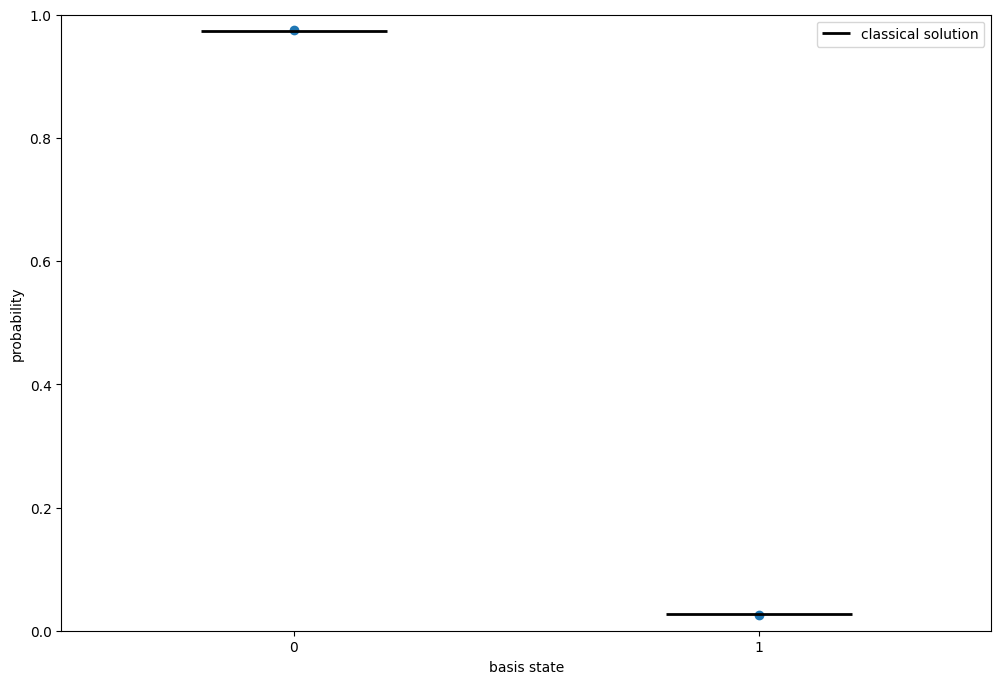

In [7]:
prob_list = []
for i in range(0, 1):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

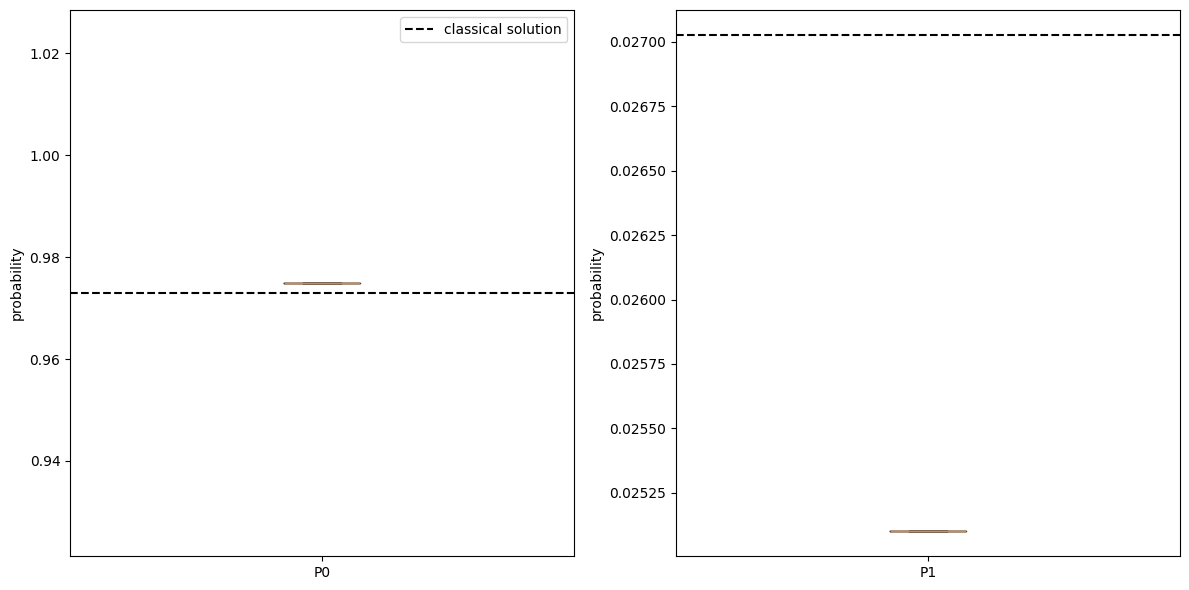

In [8]:
P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

# separate panels: P0 and P1 are ~0.6 apart, so a shared axis would squash both boxes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
plt.tight_layout()
plt.show()

# testing 1 qubit vqls on a suite of real and then complex matrices

In [9]:
random_c = lambda: random.random() + 1j * random.random()
random_r = random.random

A = np.array([
    [1, random_c()],
    [1, 1]
])
b = 1/np.sqrt(2) * np.array([
    [1],
    [1]
])
print(A)
qres = vqls.solve(A, b).solution()#.reshape(-1, 1)
cres = np.linalg.solve(A,b)
print(f"Quantum Solution: \n{qres}\n")
print(f"Classical Solution: \n{cres}\n")

# project qres onto cres
np.linalg.norm(qres - cres)

[[1.        +0.j         0.13499172+0.45995248j]
 [1.        +0.j         1.        +0.j        ]]
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [-1.571e+00]
     nit: 40
   maxcv: 0.0
    nfev: 20
Quantum Solution: 
[[ 0.70708872+0.0007401j ]
 [-0.00495011+0.00070187j]]

Classical Solution: 
[[0.70710678+0.j]
 [0.        +0.j]]



np.float64(0.005054139166644001)

In [10]:
def res_diff(x, y):
    return 1 - np.linalg.norm(x-y)

def test_vqls(b=None, shots=1):
    Ai = [ # random data set of matrices
        np.array([
            [1, random_c()],
            [random_c(), random_c()]
        ]) for _ in range(shots)
    ]

    if b is None:
        b = 1/np.sqrt(2) * np.array([
            [1],
            [1]
        ])

    accuracies = []
    for A in Ai:
        # print(b)
        q_soln = vqls.solve(A, b).solution()
        c_soln = np.linalg.solve(A, b)
        # print(f"Quantum Solution: \n{q_soln}\n")
        # print(f"Classical Solution: \n{c_soln}\n")

        diff = res_diff(q_soln, c_soln)
        # print(f"Accuracy: {diff}")
        accuracies.append(diff)

    # print(accuracies)

    return accuracies

accuracies = test_vqls()
avg_diff = sum(accuracies) / len(accuracies)

print(f"Average Quantum Solution Accuracy: {avg_diff*100:.2f}%")

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.04074634878865657
       x: [-1.749e-01]
     nit: 33
   maxcv: 0.0
    nfev: 17
Average Quantum Solution Accuracy: 69.65%


In [11]:
avg_diff, accuracies

(np.float64(0.6964765548567562), [np.float64(0.6964765548567562)])

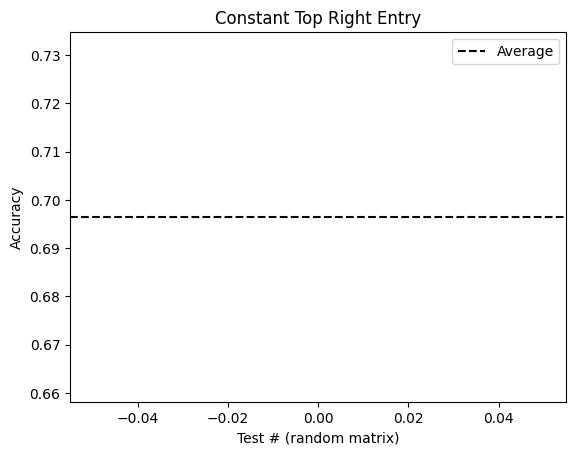

In [12]:
plt.plot(np.linspace(0, len(accuracies), 1), accuracies)
plt.axhline(avg_diff, color='black', linestyle='--', label="Average")
plt.ylabel("Accuracy")
plt.xlabel("Test # (random matrix)")
plt.title("Constant Top Right Entry")
plt.legend()

[array([[0.71127614+0.j, 0.70501552+0.j],
       [0.43597003+0.j, 0.1005488 +0.j]]), array([[0.79725426+0.j, 0.15318818+0.j],
       [0.41505091+0.j, 0.04633532+0.j]]), array([[0.81002768+0.j, 0.24406728+0.j],
       [0.74784514+0.j, 0.58350099+0.j]])]
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -6.661338147750939e-16
       x: [-2.426e+00]
     nit: 40
   maxcv: 0.0
    nfev: 23
0.9785182410665965
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -1.0880185641326534e-14
       x: [-4.167e+00]
     nit: 50
   maxcv: 0.0
    nfev: 31
0.7195679987516209
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [-1.208e+00]
     nit: 42
   maxcv: 0.0
    nfev: 20
0.9933432923451155
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun:

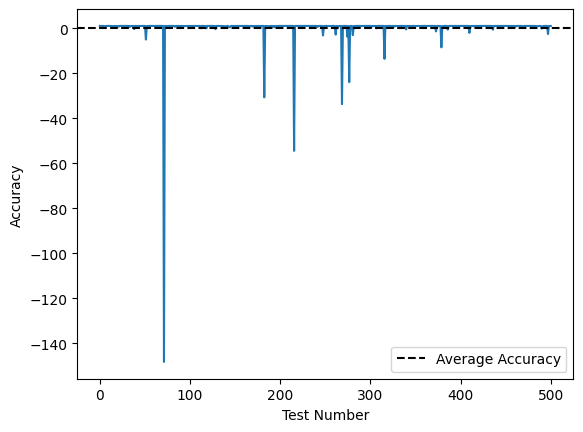

In [ ]:
vqls_ry = oasis_dla.VQLS(ansatz_type=0)
vqls_rz = oasis_dla.VQLS(ansatz_type=1)

data = vqls.generate_dataset(random_entries=[1+1j, 2+1j, 3+1j, 4+1j], shots=500)
print(data[:3])

# 1 param ansatz ry h
accuracies = vqls_ry.accuracy_test(data)
vqls_ry.plot_tests(accuracies)

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 4.0967229608668276e-14
       x: [-2.426e+00 -4.156e-07]
     nit: 48
   maxcv: 0.0
    nfev: 41
0.9746791388146888
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.1546319456101628e-13
       x: [ 1.026e+00  3.142e+00]
     nit: 58
   maxcv: 0.0
    nfev: 57
0.9366424712750245
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.176836406102666e-14
       x: [-1.208e+00  2.228e-06]
     nit: 46
   maxcv: 0.0
    nfev: 37
0.9898859197802342
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 4.440892098500626e-16
       x: [ 1.941e+00 -5.781e-08]
     nit: 73
   maxcv: 0.0
    nfev: 70
0.9534500503125625
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun

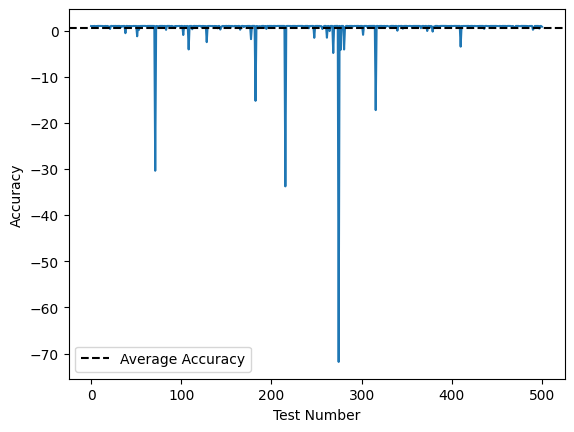

In [16]:
# 2 param ansatz rz ry h
accuracies = vqls_rz.accuracy_test(data)
vqls_rz.plot_tests(accuracies)